# SKQD on real IBM quantum hardware — large-scale SIAM example (20 orbitals, 40 qubits)

Follows the "Large-scale hardware example" of IBM Quantum's tutorial
"Sample-based Krylov quantum diagonalization of a fermionic lattice model":
https://quantum.cloud.ibm.com/docs/en/tutorials/sample-based-krylov-quantum-diagonalization

Same workflow as `skqd_siam_small.py`, scaled from 8 to 20 spatial orbitals, sampled
on a real QPU with the Qiskit Runtime SamplerV2 primitive, and compared against the
tutorial's DMRG reference energy (exact diagonalization is out of reach at this size).

Before running in "hardware" mode, save your IBM Quantum credentials once with
`QiskitRuntimeService.save_account(...)` (see README). Tutorial QPU usage estimate:
about 9 seconds on a Heron r2 processor.

What this notebook saves next to itself:
  skqd_hw_job.json      job id + backend, written right after submission
  skqd_hw_counts.json   the pooled measured bitstrings (re-analyse without the QPU)
  skqd_hw_results.json  energies per iteration, final energy, error
  skqd_hw_results.png   energy-vs-iteration and orbital-occupancy plots

## Run configuration

In [1]:
import os

# "hardware"  -> transpile for the least-busy real QPU and submit the job
# "retrieve"  -> fetch the results of an already-submitted job (set JOB_ID)
# "saved"     -> skip the QPU entirely and re-run SQD on skqd_hw_counts.json
# "dry_run"   -> no account needed: build + transpile for a fake 156-qubit Heron
#                backend and print circuit statistics, then stop
MODE = "hardware"
JOB_ID = os.environ.get("SKQD_JOB_ID", "")  # only used in "retrieve" mode

## Step 1: Map the problem to quantum circuits

In [2]:
import json
from typing import Sequence

import ffsim
import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.circuit import CircuitInstruction, Qubit
from qiskit.circuit.library import CPhaseGate, XGate, XXPlusYYGate


def siam_hamiltonian(
    norb: int,
    hopping: float,
    onsite: float,
    hybridization: float,
    chemical_potential: float,
) -> tuple[np.ndarray, np.ndarray]:
    """Hamiltonian (h1e, h2e) for the single-impurity Anderson model."""
    impurity_orb = 0
    h1e = np.zeros((norb, norb))
    np.fill_diagonal(h1e[:, 1:], -hopping)
    np.fill_diagonal(h1e[1:, :], -hopping)
    h1e[impurity_orb, impurity_orb + 1] = -hybridization
    h1e[impurity_orb + 1, impurity_orb] = -hybridization
    h1e[impurity_orb, impurity_orb] = chemical_potential
    h2e = np.zeros((norb, norb, norb, norb))
    h2e[impurity_orb, impurity_orb, impurity_orb, impurity_orb] = onsite
    return h1e, h2e


def momentum_basis(norb: int) -> np.ndarray:
    """Orbital rotation from the position basis to the momentum basis."""
    n_bath = norb - 1
    hopping_matrix = np.zeros((n_bath, n_bath))
    np.fill_diagonal(hopping_matrix[:, 1:], -1)
    np.fill_diagonal(hopping_matrix[1:, :], -1)
    _, vecs = np.linalg.eigh(hopping_matrix)
    orbital_rotation = np.zeros((norb, norb))
    orbital_rotation[0, 0] = 1
    orbital_rotation[1:, 1:] = vecs
    new_index = n_bath // 2
    perm = np.r_[1 : (new_index + 1), 0, (new_index + 1) : norb]
    return orbital_rotation[:, perm]


def rotated(
    h1e: np.ndarray, h2e: np.ndarray, orbital_rotation: np.ndarray
) -> tuple[np.ndarray, np.ndarray]:
    """Rotate the orbital basis of a Hamiltonian."""
    h1e_rotated = np.einsum(
        "ab,Aa,Bb->AB", h1e, orbital_rotation, orbital_rotation.conj(),
        optimize="greedy",
    )
    h2e_rotated = np.einsum(
        "abcd,Aa,Bb,Cc,Dd->ABCD", h2e,
        orbital_rotation, orbital_rotation.conj(),
        orbital_rotation, orbital_rotation.conj(),
        optimize="greedy",
    )
    return h1e_rotated, h2e_rotated


def prepare_initial_state(qubits: Sequence[Qubit], norb: int, nocc: int):
    """Superposition of excitations near the Fermi level, per spin species."""
    assert norb >= 8
    x_gate = XGate()
    rot = XXPlusYYGate(0.5 * np.pi, -0.5 * np.pi)
    for i in range(nocc):
        yield CircuitInstruction(x_gate, [qubits[i]])
        yield CircuitInstruction(x_gate, [qubits[norb + i]])
    for i in range(3):
        for j in range(nocc - i - 1, nocc + i, 2):
            yield CircuitInstruction(rot, [qubits[j], qubits[j + 1]])
            yield CircuitInstruction(rot, [qubits[norb + j], qubits[norb + j + 1]])
    yield CircuitInstruction(rot, [qubits[j + 1], qubits[j + 2]])
    yield CircuitInstruction(rot, [qubits[norb + j + 1], qubits[norb + j + 2]])


def trotter_step(
    qubits: Sequence[Qubit],
    time_step: float,
    one_body_evolution: np.ndarray,
    h2e: np.ndarray,
    impurity_index: int,
    norb: int,
):
    """One second-order Trotter step."""
    onsite = h2e[impurity_index, impurity_index, impurity_index, impurity_index]
    yield CircuitInstruction(
        CPhaseGate(-0.5 * time_step * onsite),
        [qubits[impurity_index], qubits[norb + impurity_index]],
    )
    yield CircuitInstruction(
        ffsim.qiskit.OrbitalRotationJW(norb, one_body_evolution), qubits
    )
    yield CircuitInstruction(
        CPhaseGate(-0.5 * time_step * onsite),
        [qubits[impurity_index], qubits[norb + impurity_index]],
    )

In [3]:
# Model parameters (tutorial's large-scale values)
norb = 20
nelec = (norb // 2, norb // 2)
n_bath = norb - 1
hybridization = 1.0
hopping = 1.0
onsite = 10.0
chemical_potential = -0.5 * onsite

h1e, h2e = siam_hamiltonian(
    norb=norb,
    hopping=hopping,
    onsite=onsite,
    hybridization=hybridization,
    chemical_potential=chemical_potential,
)
orbital_rotation = momentum_basis(norb)
h1e_momentum, h2e_momentum = rotated(h1e, h2e, orbital_rotation.T.conj())
impurity_index = n_bath // 2

# DMRG reference energy computed separately by the tutorial authors
reference_energy = -28.70659686

# Algorithm parameters
time_step = 0.2
krylov_dim = 8
shots = 500

In [4]:
qubits = QuantumRegister(2 * norb, name="q")
circuit = QuantumCircuit(qubits)
for instruction in prepare_initial_state(qubits, norb=norb, nocc=norb // 2):
    circuit.append(instruction)
circuit.measure_all()
circuits = [circuit.copy()]

one_body_evolution = scipy.linalg.expm(-1j * time_step * h1e_momentum)
for i in range(krylov_dim - 1):
    circuit.remove_final_measurements()
    for instruction in trotter_step(
        qubits, time_step, one_body_evolution, h2e_momentum, impurity_index, norb
    ):
        circuit.append(instruction)
    circuit.measure_all()
    circuits.append(circuit.copy())

print(f"Built {len(circuits)} Krylov circuits on {circuits[0].num_qubits} qubits")

Built 8 Krylov circuits on 40 qubits


## Step 2: Optimize for the target QPU

In [5]:
from qiskit.transpiler import generate_preset_pass_manager


def two_qubit_count(circ: QuantumCircuit) -> int:
    return sum(1 for inst in circ.data if inst.operation.num_qubits == 2)


def print_circuit_stats(isa_circuits) -> list[dict]:
    stats = []
    print(f"{'k':>2} {'depth':>7} {'2q gates':>9}")
    for k, c in enumerate(isa_circuits):
        s = {"k": k, "depth": c.depth(), "two_qubit_gates": two_qubit_count(c)}
        stats.append(s)
        print(f"{k:>2} {s['depth']:>7} {s['two_qubit_gates']:>9}")
    return stats


service = None
backend = None
if MODE in ("hardware", "retrieve"):
    from qiskit_ibm_runtime import QiskitRuntimeService

    service = QiskitRuntimeService()  # loads the account saved with save_account()

if MODE == "hardware":
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=127)
    print(f"Using backend {backend.name}")
elif MODE == "dry_run":
    from qiskit_ibm_runtime.fake_provider import FakeFez

    backend = FakeFez()  # 156-qubit Heron r2 snapshot; nothing is submitted
    print(f"Dry run: transpiling for fake backend {backend.name}")

circuit_stats = None
if MODE in ("hardware", "dry_run"):
    pass_manager = generate_preset_pass_manager(optimization_level=3, backend=backend)
    isa_circuits = pass_manager.run(circuits)
    circuit_stats = print_circuit_stats(isa_circuits)

if MODE == "dry_run":
    with open("skqd_hw_dryrun_stats.json", "w") as f:
        json.dump({"backend": backend.name, "circuits": circuit_stats}, f, indent=2)
    raise SystemExit("Dry run finished: circuits transpile; nothing was submitted.")

Using backend ibm_fez
 k   depth  2q gates
 0      36        28
 1     455       840
 2     846      1579
 3    1733      2092
 4    1638      3011
 5    1391      3316
 6    2377      4223
 7    2402      4940


## Step 3: Execute on the QPU with SamplerV2

Every Krylov circuit is sampled, and all shots are pooled into one set of bitstrings.

In [6]:
from qiskit.primitives import BitArray

if MODE == "hardware":
    from qiskit_ibm_runtime import SamplerV2 as Sampler

    sampler = Sampler(backend)
    sampler.options.environment.job_tags = ["TUT_SKQD"]
    job = sampler.run(isa_circuits, shots=shots)
    # Save the job id immediately, so the results can be fetched later if the
    # kernel dies while the job waits in the queue (use MODE="retrieve").
    with open("skqd_hw_job.json", "w") as f:
        json.dump({"job_id": job.job_id(), "backend": backend.name}, f, indent=2)
    print(f"Submitted job {job.job_id()} — waiting for results...")
elif MODE == "retrieve":
    job = service.job(JOB_ID)
    print(f"Retrieved job {JOB_ID} on {job.backend().name}")

if MODE in ("hardware", "retrieve"):
    bit_array = BitArray.concatenate_shots([res.data.meas for res in job.result()])
    with open("skqd_hw_counts.json", "w") as f:
        json.dump(bit_array.get_counts(), f)
elif MODE == "saved":
    with open("skqd_hw_counts.json") as f:
        bit_array = BitArray.from_counts(json.load(f), num_bits=2 * norb)

print(f"Total shots: {bit_array.num_shots}")

Submitted job dbioohune4hc73bf3270 — waiting for results...
Total shots: 4000


## Step 4: Post-process with SQD (configuration recovery + diagonalization)

In [7]:
from qiskit_addon_sqd.fermion import SCIResult, diagonalize_fermionic_hamiltonian

result_history = []


def callback(results: list[SCIResult]):
    result_history.append(results)
    print(f"Iteration {len(result_history)}")
    for i, r in enumerate(results):
        print(f"\tSubsample {i}")
        print(f"\t\tEnergy: {r.energy}")
        print(f"\t\tSubspace dimension: {np.prod(r.sci_state.amplitudes.shape)}")


rng = np.random.default_rng(24)
result = diagonalize_fermionic_hamiltonian(
    h1e_momentum,
    h2e_momentum,
    bit_array,
    samples_per_batch=100,
    norb=norb,
    nelec=nelec,
    num_batches=3,
    max_iterations=5,
    symmetrize_spin=True,
    callback=callback,
    seed=rng,
)

Iteration 1
	Subsample 0
		Energy: -28.614166676184162
		Subspace dimension: 11664
	Subsample 1
		Energy: -28.613949332374002
		Subspace dimension: 11664
	Subsample 2
		Energy: -28.61443496813361
		Subspace dimension: 11025
Iteration 2
	Subsample 0
		Energy: -28.665647065245896
		Subspace dimension: 42025
	Subsample 1
		Energy: -28.652270431508327
		Subspace dimension: 37636
	Subsample 2
		Energy: -28.622983984610492
		Subspace dimension: 38809
Iteration 3
	Subsample 0
		Energy: -28.665827345151662
		Subspace dimension: 40804
	Subsample 1
		Energy: -28.668369896122833
		Subspace dimension: 39601
	Subsample 2
		Energy: -28.667139568906094
		Subspace dimension: 38025
Iteration 4
	Subsample 0
		Energy: -28.67528051744523
		Subspace dimension: 45369
	Subsample 1
		Energy: -28.688691244594676
		Subspace dimension: 38025
	Subsample 2
		Energy: -28.672449204994336
		Subspace dimension: 40804
Iteration 5
	Subsample 0
		Energy: -28.695204228753433
		Subspace dimension: 48841
	Subsample 1
		Ener

## Results

Reference energy (DMRG): -28.70660
SQD energy: -28.69574
Absolute error: 0.01085


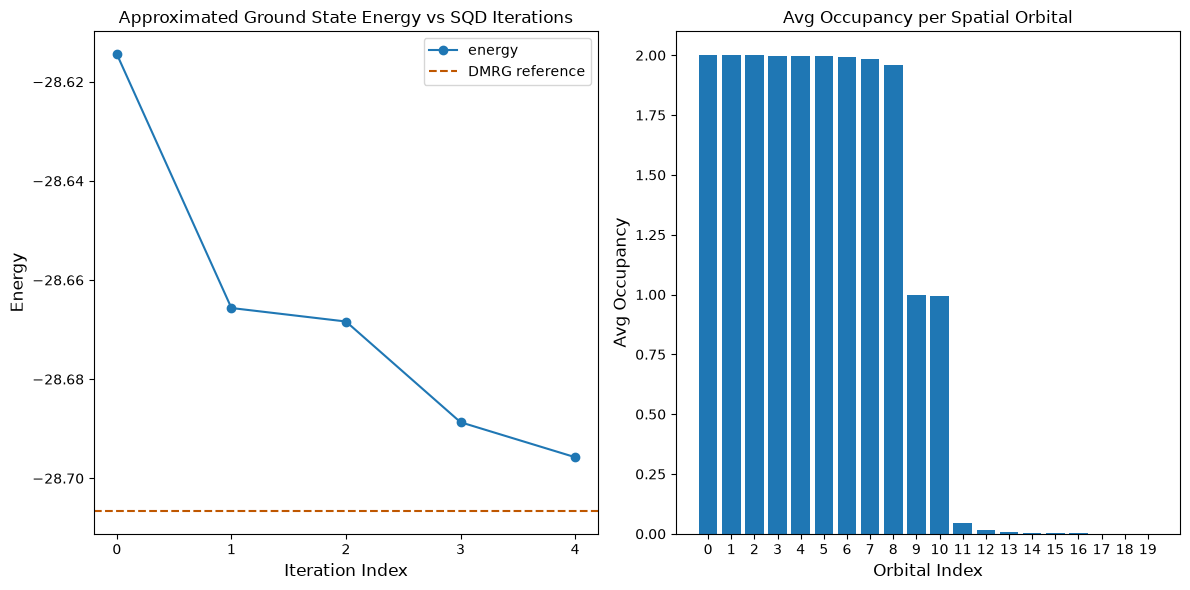

In [8]:
min_es = [min(r, key=lambda res: res.energy).energy for r in result_history]
min_id, min_e = min(enumerate(min_es), key=lambda x: x[1])
dims = [
    int(np.prod(min(r, key=lambda res: res.energy).sci_state.amplitudes.shape))
    for r in result_history
]

x1 = range(len(result_history))
y2 = np.sum(result.orbital_occupancies, axis=0)
x2 = range(len(y2))

fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].plot(x1, min_es, label="energy", marker="o")
axs[0].set_xticks(x1)
axs[0].set_xticklabels(x1)
axs[0].axhline(y=reference_energy, color="#BF5700", linestyle="--", label="DMRG reference")
axs[0].set_title("Approximated Ground State Energy vs SQD Iterations")
axs[0].set_xlabel("Iteration Index", fontdict={"fontsize": 12})
axs[0].set_ylabel("Energy", fontdict={"fontsize": 12})
axs[0].legend()
axs[1].bar(x2, y2, width=0.8)
axs[1].set_xticks(x2)
axs[1].set_xticklabels(x2)
axs[1].set_title("Avg Occupancy per Spatial Orbital")
axs[1].set_xlabel("Orbital Index", fontdict={"fontsize": 12})
axs[1].set_ylabel("Avg Occupancy", fontdict={"fontsize": 12})

print(f"Reference energy (DMRG): {reference_energy:.5f}")
print(f"SQD energy: {min_e:.5f}")
print(f"Absolute error: {abs(min_e - reference_energy):.5f}")
plt.tight_layout()
plt.savefig("skqd_hw_results.png", dpi=150)
plt.show()

In [9]:
# Cross-check the energy from the returned state's reduced density matrices
rdm1 = result.sci_state.rdm(rank=1, spin_summed=True)
rdm2 = result.sci_state.rdm(rank=2, spin_summed=True)
energy_rdm = np.sum(h1e_momentum * rdm1) + 0.5 * np.sum(h2e_momentum * rdm2)
print(f"Recomputed energy from RDMs: {energy_rdm:.5f}")

summary = {
    "mode": MODE,
    "backend": backend.name if backend is not None else None,
    "norb": norb,
    "krylov_dim": krylov_dim,
    "time_step": time_step,
    "shots_per_circuit": shots,
    "total_shots": int(bit_array.num_shots),
    "reference_energy_dmrg": reference_energy,
    "best_energy_per_iteration": [float(e) for e in min_es],
    "subspace_dim_per_iteration": dims,
    "sqd_energy": float(min_e),
    "recomputed_energy_rdm": float(energy_rdm),
    "absolute_error": float(abs(min_e - reference_energy)),
    "transpiled_circuits": circuit_stats,
}
with open("skqd_hw_results.json", "w") as f:
    json.dump(summary, f, indent=2)
print("Saved skqd_hw_results.json")

Recomputed energy from RDMs: -28.69574
Saved skqd_hw_results.json
